
# Chapter 1 — Introduction
Notebook minh họa cấu trúc dữ liệu phi tuyến và hướng tiếp cận của Diffusion Maps.

In [5]:
!git clone https://github.com/ntanphu/ML-HK261.git
%cd /content/ML-HK261

fatal: destination path 'ML-HK261' already exists and is not an empty directory.
/content/ML-HK261


In [6]:
!ls -la pictures

-rw-r--r-- 1 root root 1 Nov 19 05:18 pictures


1.1. Minh họa cấu trúc đa tạp phi tuyến

Khởi tạo $n=1800$ điểm Swiss Roll và trực quan hóa tọa độ ba chiều cùng tọa độ nội tại hai chiều. Qua đó minh họa sự khác biệt giữa số chiều biểu diễn và số chiều nội tại.

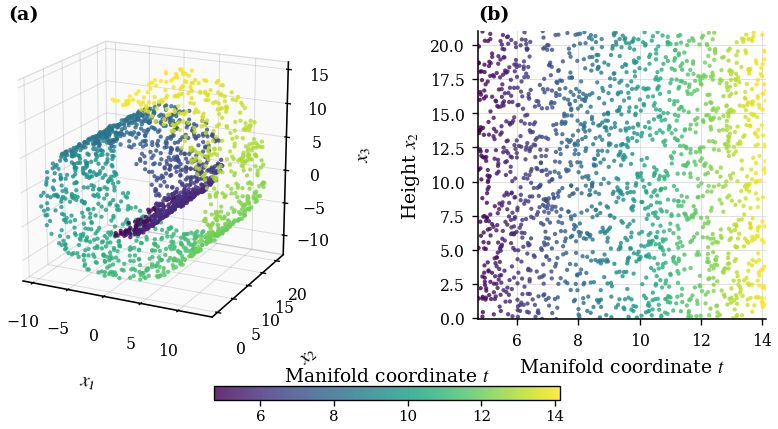

Saved PDF: /content/pictures/fig1_1_swiss_roll.pdf
Saved PNG: /content/pictures/fig1_1_swiss_roll.png


In [7]:
# ============================================================
# Swiss Roll
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from sklearn.datasets import make_swiss_roll

# ---------- Publication style ----------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",

    "font.size": 8.5,
    "axes.labelsize": 9.0,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,

    "axes.linewidth": 0.75,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.width": 0.65,
    "ytick.major.width": 0.65,
    "xtick.major.size": 3.0,
    "ytick.major.size": 3.0,

    # Embed fonts in PDF
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ---------- Generate data ----------
n = 1800

X_roll, t_roll = make_swiss_roll(
    n_samples=n,
    noise=0.10,
    random_state=42
)

norm = Normalize(
    vmin=float(t_roll.min()),
    vmax=float(t_roll.max())
)

# ---------- Figure layout ----------
# Compact figure suitable for a two-column paper.
fig = plt.figure(figsize=(6.4, 2.9))

# Two panels with exactly the same physical dimensions.
left_panel  = [0.105, 0.25, 0.30, 0.662]
right_panel = [0.595, 0.25, 0.30, 0.662]

ax1 = fig.add_axes(left_panel, projection="3d")
ax2 = fig.add_axes(right_panel)

scatter_style = {
    "cmap": "viridis",
    "norm": norm,
    "s": 4.2,
    "alpha": 0.82,
    "linewidths": 0,
    "rasterized": True,
}

# ---------- Panel (a): ambient 3D space ----------
sc1 = ax1.scatter(
    X_roll[:, 0],
    X_roll[:, 1],
    X_roll[:, 2],
    c=t_roll,
    depthshade=False,
    **scatter_style
)

# The zoom argument is supported by current Google Colab Matplotlib.
try:
    ax1.set_box_aspect((1.0, 0.88, 1.0), zoom=1.16)
except TypeError:
    # Compatibility fallback for older Matplotlib versions.
    ax1.set_box_aspect((1.0, 0.88, 1.0))

ax1.view_init(elev=18, azim=-64)

ax1.set_xlabel(r"$x_1$", labelpad=1.5)
ax1.set_ylabel(r"$x_2$", labelpad=1.5)
ax1.set_zlabel(r"$x_3$", labelpad=1.5)
ax1.tick_params(pad=0.5)

# Light 3D panes and grid.
for axis in (ax1.xaxis, ax1.yaxis, ax1.zaxis):
    axis.pane.fill = True
    axis.pane.set_facecolor((0.97, 0.97, 0.97, 1.0))
    axis.pane.set_edgecolor((0.72, 0.72, 0.72, 1.0))
    axis._axinfo["grid"].update({
        "color": (0.55, 0.55, 0.55, 0.28),
        "linewidth": 0.45,
    })

# ---------- Panel (b): intrinsic coordinates ----------
ax2.scatter(
    t_roll,
    X_roll[:, 1],
    c=t_roll,
    **scatter_style
)

ax2.set_xlabel(r"Manifold coordinate $t$")
ax2.set_ylabel(r"Height $x_2$")

# Make panel (b) physically square like panel (a).
ax2.set_box_aspect(1.0)

ax2.set_xlim(float(t_roll.min()), float(t_roll.max()))
ax2.set_ylim(
    float(X_roll[:, 1].min()),
    float(X_roll[:, 1].max())
)

ax2.grid(
    True,
    color="0.84",
    linewidth=0.45,
    alpha=0.80
)
ax2.set_axisbelow(True)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

# ---------- Panel labels ----------
# Labels are outside the plotting regions, preventing overlap.
fig.text(
    left_panel[0],
    0.93,
    "(a)",
    ha="left",
    va="bottom",
    fontsize=9.2,
    fontweight="bold"
)

fig.text(
    right_panel[0],
    0.93,
    "(b)",
    ha="left",
    va="bottom",
    fontsize=9.2,
    fontweight="bold"
)

# ---------- Shared colorbar ----------
cbar_ax = fig.add_axes([0.32, 0.065, 0.36, 0.032])

cbar = fig.colorbar(
    sc1,
    cax=cbar_ax,
    orientation="horizontal"
)

# Put the label above the colorbar to avoid bottom clipping.
cbar.ax.xaxis.set_label_position("top")
cbar.set_label(
    r"Manifold coordinate $t$",
    labelpad=2.0
)
cbar.ax.tick_params(labelsize=7.2, pad=1.5)
cbar.outline.set_linewidth(0.65)

# ---------- Save outputs ----------
output_dir = "/content/pictures"
os.makedirs(output_dir, exist_ok=True)

pdf_path = os.path.join(output_dir, "fig1_1_swiss_roll.pdf")
png_path = os.path.join(output_dir, "fig1_1_swiss_roll.png")

# Do not use bbox_inches="tight"; it can recrop the canvas
# and make the two panels appear asymmetrical.
fig.savefig(
    pdf_path,
    dpi=600,
    bbox_inches=None,
    pad_inches=0
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches=None,
    pad_inches=0
)

plt.show()

print("Saved PDF:", pdf_path)
print("Saved PNG:", png_path)

1.2. Hệ động lực Lorenz

Mô phỏng hệ Lorenz với $\sigma=10$, $\rho=28$ và $\beta=8/3$ để minh họa cấu trúc phi tuyến của quỹ đạo trong không gian pha.

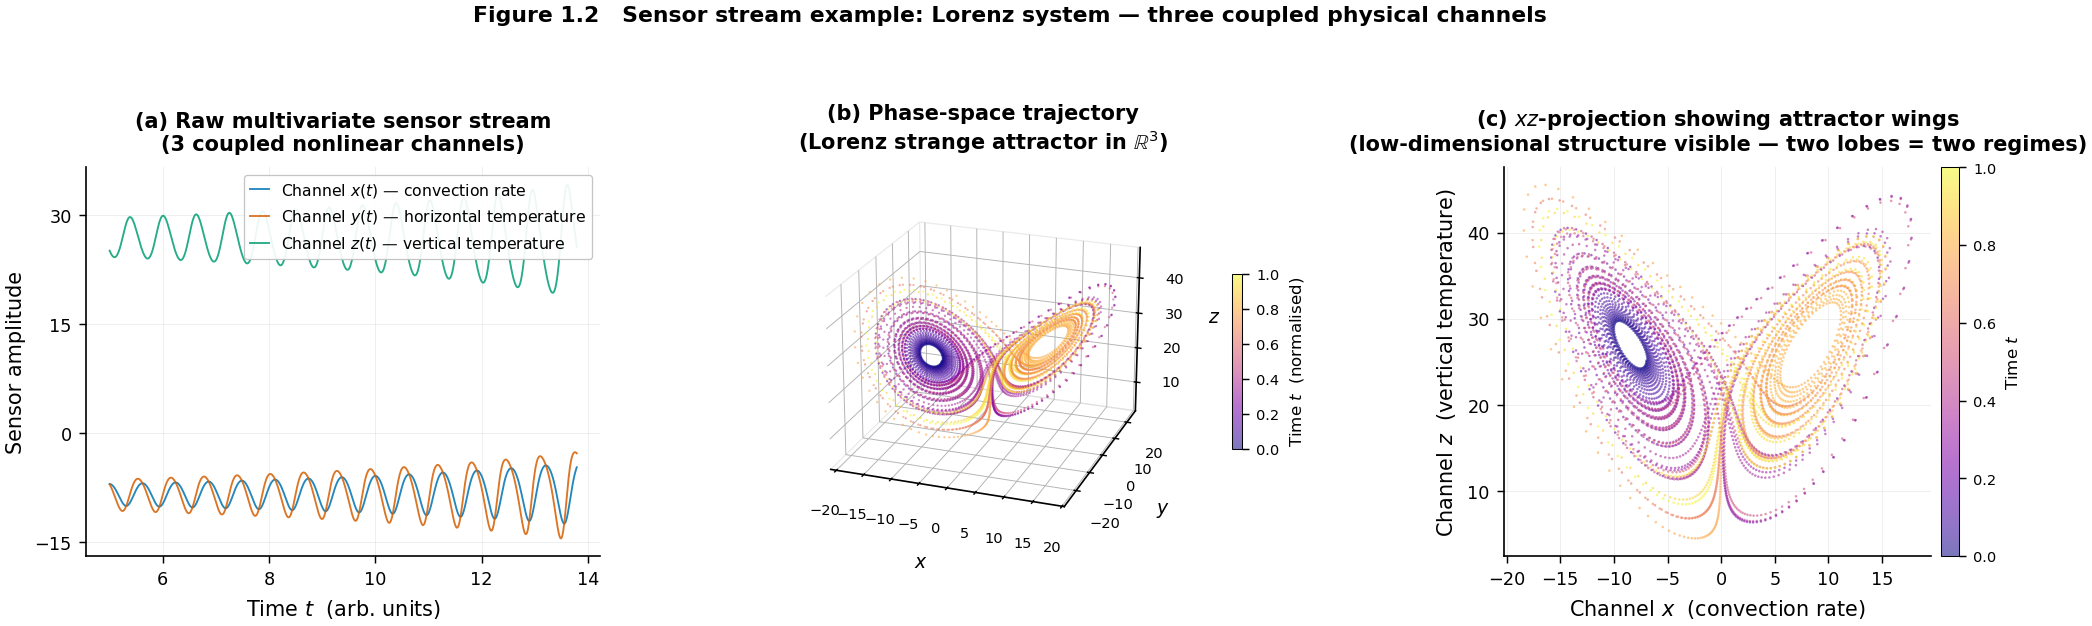

Figure 1.2 saved  (fig1_2_sensor_lorenz.pdf, 300 DPI)


In [ ]:

# ============================================================
# Figure 1.2 — Lorenz sensor stream
# Compact three-panel layout for Google Colab / Q1 paper
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from matplotlib.colors import Normalize
from scipy.integrate import solve_ivp


# ------------------------------------------------------------
# 1. Publication style
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",

    "font.size": 8.2,
    "axes.labelsize": 8.7,
    "xtick.labelsize": 7.2,
    "ytick.labelsize": 7.2,
    "legend.fontsize": 6.8,

    "axes.linewidth": 0.75,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.width": 0.65,
    "ytick.major.width": 0.65,
    "xtick.major.size": 3.0,
    "ytick.major.size": 3.0,

    # Embed fonts in PDF
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


# ------------------------------------------------------------
# 2. Lorenz system
# ------------------------------------------------------------
def lorenz_system(t, state, sigma=10.0, rho=28.0, beta=8/3):
    x, y, z = state

    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z

    return [dx, dy, dz]


sol = solve_ivp(
    lorenz_system,
    t_span=(0.0, 60.0),
    y0=[1.0, 0.0, 0.0],
    method="DOP853",
    t_eval=np.linspace(5.0, 60.0, 5000),
    rtol=1e-10,
    atol=1e-12
)

if not sol.success:
    raise RuntimeError(sol.message)

t_lor = sol.t
X_lor = sol.y.T

# Time is kept in physical units rather than normalised units.
time_norm = Normalize(
    vmin=float(t_lor.min()),
    vmax=float(t_lor.max())
)

# Colour-blind-friendly line colours.
channel_colors = [
    "#0072B2",  # blue
    "#D55E00",  # vermilion
    "#009E73",  # green
]

channel_labels = [
    r"$x(t)$",
    r"$y(t)$",
    r"$z(t)$",
]


# ------------------------------------------------------------
# 3. Figure layout
# ------------------------------------------------------------
# Full-width but compact figure.
fig = plt.figure(figsize=(7.2, 3.0))

# All three panels have exactly the same width and height.
panel_a = [0.0550, 0.32, 0.245, 0.60]
panel_b = [0.3775, 0.32, 0.245, 0.60]
panel_c = [0.7000, 0.32, 0.245, 0.60]

ax_ts = fig.add_axes(panel_a)
ax_3d = fig.add_axes(panel_b, projection="3d")
ax_2d = fig.add_axes(panel_c)


# ------------------------------------------------------------
# 4. Panel (a): multivariate sensor stream
# ------------------------------------------------------------
n_show = 800

for channel, color, label in zip(
    range(3),
    channel_colors,
    channel_labels
):
    ax_ts.plot(
        t_lor[:n_show],
        X_lor[:n_show, channel],
        color=color,
        linewidth=0.70,
        alpha=0.88,
        label=label
    )

ax_ts.set_xlabel(r"Time $t$")
ax_ts.set_ylabel("Sensor amplitude")

ax_ts.yaxis.set_major_locator(
    ticker.MaxNLocator(nbins=5)
)
ax_ts.xaxis.set_major_locator(
    ticker.MaxNLocator(nbins=5)
)

ax_ts.grid(
    True,
    color="0.86",
    linewidth=0.45,
    alpha=0.85
)
ax_ts.set_axisbelow(True)

ax_ts.spines["top"].set_visible(False)
ax_ts.spines["right"].set_visible(False)

ax_ts.legend(
    loc="upper right",
    ncol=1,
    frameon=True,
    fancybox=False,
    framealpha=0.92,
    edgecolor="0.70",
    facecolor="white",
    handlelength=1.25,
    handletextpad=0.45,
    borderpad=0.35,
    labelspacing=0.25
)


# ------------------------------------------------------------
# 5. Panel (b): 3D Lorenz attractor
# ------------------------------------------------------------
scatter_style = {
    "cmap": "plasma",
    "norm": time_norm,
    "s": 1.6,
    "alpha": 0.62,
    "linewidths": 0,
    "rasterized": True,
}

sc_3d = ax_3d.scatter(
    X_lor[:, 0],
    X_lor[:, 1],
    X_lor[:, 2],
    c=t_lor,
    depthshade=False,
    **scatter_style
)

# Match the apparent size of the 3D attractor to the other panels.
try:
    ax_3d.set_box_aspect(
        (1.0, 1.0, 0.90),
        zoom=1.12
    )
except TypeError:
    ax_3d.set_box_aspect((1.0, 1.0, 0.90))

ax_3d.view_init(elev=22, azim=290)

ax_3d.set_xlabel(r"$x$", labelpad=1.0)
ax_3d.set_ylabel(r"$y$", labelpad=1.0)
ax_3d.set_zlabel(r"$z$", labelpad=1.0)
ax_3d.tick_params(pad=0.3)

# Light background panes.
for axis in (ax_3d.xaxis, ax_3d.yaxis, ax_3d.zaxis):
    axis.pane.fill = True
    axis.pane.set_facecolor((0.97, 0.97, 0.97, 1.0))
    axis.pane.set_edgecolor((0.74, 0.74, 0.74, 1.0))
    axis._axinfo["grid"].update({
        "color": (0.55, 0.55, 0.55, 0.25),
        "linewidth": 0.40,
    })


# ------------------------------------------------------------
# 6. Panel (c): x-z projection
# ------------------------------------------------------------
ax_2d.scatter(
    X_lor[:, 0],
    X_lor[:, 2],
    c=t_lor,
    **scatter_style
)

ax_2d.set_xlabel(r"Channel $x(t)$")
ax_2d.set_ylabel(r"Channel $z(t)$")

# Keep the physical plotting area equal to the other panels.
ax_2d.set_box_aspect(1.0)

ax_2d.xaxis.set_major_locator(
    ticker.MaxNLocator(nbins=5)
)
ax_2d.yaxis.set_major_locator(
    ticker.MaxNLocator(nbins=5)
)

ax_2d.grid(
    True,
    color="0.86",
    linewidth=0.45,
    alpha=0.85
)
ax_2d.set_axisbelow(True)

ax_2d.spines["top"].set_visible(False)
ax_2d.spines["right"].set_visible(False)


# ------------------------------------------------------------
# 7. Panel labels outside the data regions
# ------------------------------------------------------------
panel_label_style = {
    "ha": "left",
    "va": "bottom",
    "fontsize": 9.2,
    "fontweight": "bold",
}

fig.text(panel_a[0], 0.945, "(a)", **panel_label_style)
fig.text(panel_b[0], 0.945, "(b)", **panel_label_style)
fig.text(panel_c[0], 0.945, "(c)", **panel_label_style)


# ------------------------------------------------------------
# 8. Shared colorbar for panels (b) and (c)
# ------------------------------------------------------------
cbar_ax = fig.add_axes([
    0.450,   # left
    0.055,   # bottom
    0.420,   # width
    0.025    # height
])

cbar = fig.colorbar(
    sc_3d,
    cax=cbar_ax,
    orientation="horizontal"
)

# Place label above colorbar to prevent bottom clipping.
cbar.ax.xaxis.set_label_position("top")
cbar.set_label(r"Time $t$", labelpad=2.0)

cbar.ax.tick_params(
    labelsize=7.0,
    pad=1.5
)
cbar.outline.set_linewidth(0.65)


# ------------------------------------------------------------
# 9. Save outputs
# ------------------------------------------------------------
output_dir = "/content/pictures"
os.makedirs(output_dir, exist_ok=True)

pdf_path = os.path.join(
    output_dir,
    "fig1_2_sensor_lorenz.pdf"
)

png_path = os.path.join(
    output_dir,
    "fig1_2_sensor_lorenz.png"
)

# Avoid bbox_inches="tight" because the 3D labels can cause
# asymmetric recropping of the three-panel layout.
fig.savefig(
    pdf_path,
    dpi=600,
    bbox_inches=None,
    pad_inches=0
)

fig.savefig(
    png_path,
    dpi=600,
    bbox_inches=None,
    pad_inches=0
)

plt.show()

print("Saved PDF:", pdf_path)
print("Saved PNG:", png_path)


---
## 1.3 Conventional Linear Solution: PCA



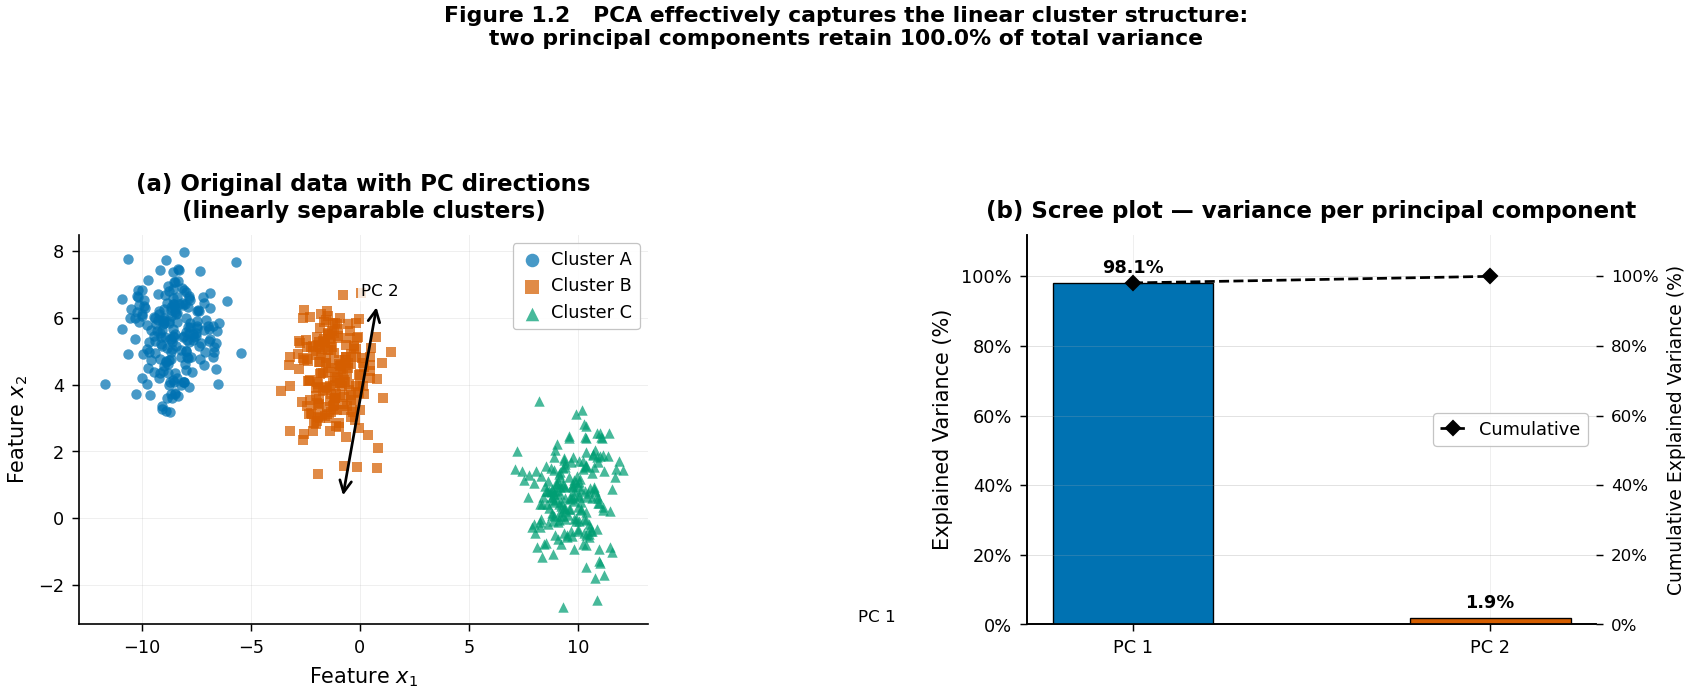

Figure 1.2 saved  (fig1_2_pca_linear.pdf, 300 DPI)


In [ ]:

# ── Figure 1.3  PCA on linearly separable data ────────────────────────────
X_blobs, y_blobs = make_blobs(n_samples=600, centers=3,
                               cluster_std=1.05, random_state=7)
pca_2d  = PCA(n_components=2)
X_pca2  = pca_2d.fit_transform(X_blobs)
varexp  = pca_2d.explained_variance_ratio_
cumvar  = np.cumsum(varexp)

CL_COLORS  = [CB['blue'], CB['red'], CB['green']]
CL_MARKERS = ['o', 's', '^']
CL_NAMES   = ['Cluster A', 'Cluster B', 'Cluster C']

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))

# ── Panel (a): original scatter + PC arrows ────────────────────────────────
for k in range(3):
    mask = y_blobs == k
    axes[0].scatter(X_blobs[mask, 0], X_blobs[mask, 1],
                    c=CL_COLORS[k], marker=CL_MARKERS[k],
                    s=25, alpha=0.72, linewidths=0,
                    label=CL_NAMES[k], zorder=3)

mu = X_blobs.mean(axis=0)
for comp, ev, lbl in zip(pca_2d.components_,
                          pca_2d.explained_variance_,
                          ['PC 1', 'PC 2']):
    scale = 2.8 * np.sqrt(ev)
    axes[0].annotate(
        '', xy=mu + scale * comp, xytext=mu - scale * comp,
        arrowprops=dict(arrowstyle='<->', color='black',
                        lw=1.3, mutation_scale=14))
    axes[0].text(*(mu + scale * comp * 1.12), lbl,
                 fontsize=8, ha='center', va='center',
                 bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.8))

axes[0].set_xlabel('Feature $x_1$')
axes[0].set_ylabel('Feature $x_2$')
axes[0].set_title('(a) Original data with PC directions\n'
                  '(linearly separable clusters)')
axes[0].legend(loc='upper right', framealpha=0.92, edgecolor='0.75',
               markerscale=1.3, handletextpad=0.4)

# ── Panel (b): scree plot with cumulative variance ────────────────────────
pc_labels = [f'PC {i+1}' for i in range(len(varexp))]
bars = axes[1].bar(pc_labels, varexp * 100,
                   color=[CB['blue'], CB['red']],
                   edgecolor='black', linewidth=0.65, width=0.45, zorder=3)
for bar, v in zip(bars, varexp):
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 v * 100 + 1.8,
                 f'{v*100:.1f}%', ha='center', va='bottom',
                 fontsize=8.5, fontweight='bold')

ax_twin = axes[1].twinx()
ax_twin.plot(pc_labels, cumvar * 100,
             color=CB['black'], linestyle='--', marker='D',
             markersize=5, linewidth=1.3, label='Cumulative', zorder=4)
ax_twin.set_ylabel('Cumulative Explained Variance (%)', fontsize=9)
ax_twin.set_ylim(0, 112)
ax_twin.spines['top'].set_visible(False)
ax_twin.spines['right'].set_linewidth(0.8)
ax_twin.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=100, decimals=0))
ax_twin.tick_params(labelsize=8)
ax_twin.legend(loc='center right', fontsize=8.5)

axes[1].set_ylabel('Explained Variance (%)')
axes[1].set_ylim(0, 112)
axes[1].yaxis.set_major_formatter(ticker.PercentFormatter(xmax=100, decimals=0))
axes[1].set_title('(b) Scree plot — variance per principal component')

fig.suptitle(
    'Figure 1.3   PCA effectively captures the linear cluster structure:\n'
    f'two principal components retain {cumvar[-1]*100:.1f}% of total variance',
    fontsize=10.5, fontweight='bold')
# rect=[left, bottom, right, top]: reserve top 13% of figure height for suptitle
fig.tight_layout(rect=[0, 0, 1, 0.87])

fig.savefig('pictures/fig1_3_pca_linear.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Figure 1.3 saved  (fig1_3_pca_linear.pdf, 300 DPI)")


---
## 1.3 Limitations of PCA in Nonlinear Structures

PCA is **fundamentally linear**. When data resides on curved manifolds, linear projections can:

| Problem | Consequence |
|---------|-------------|
| Distort neighbourhood relationships | Nearby-on-manifold points map far apart |
| Collapse meaningful transitions | Regime changes become indistinguishable |
| Mix unrelated local structures | Principal components conflate independent variations |
| Artificially bring distant points close | Downstream clustering becomes unstable |

> *"Points that are distant along the manifold may appear **artificially close** after projection."*

The figure below makes this concrete: PCA projection of the Two-Moon dataset, a classic nonlinear structure fails to separate the two clusters, while the true class structure is obvious in 2-D.

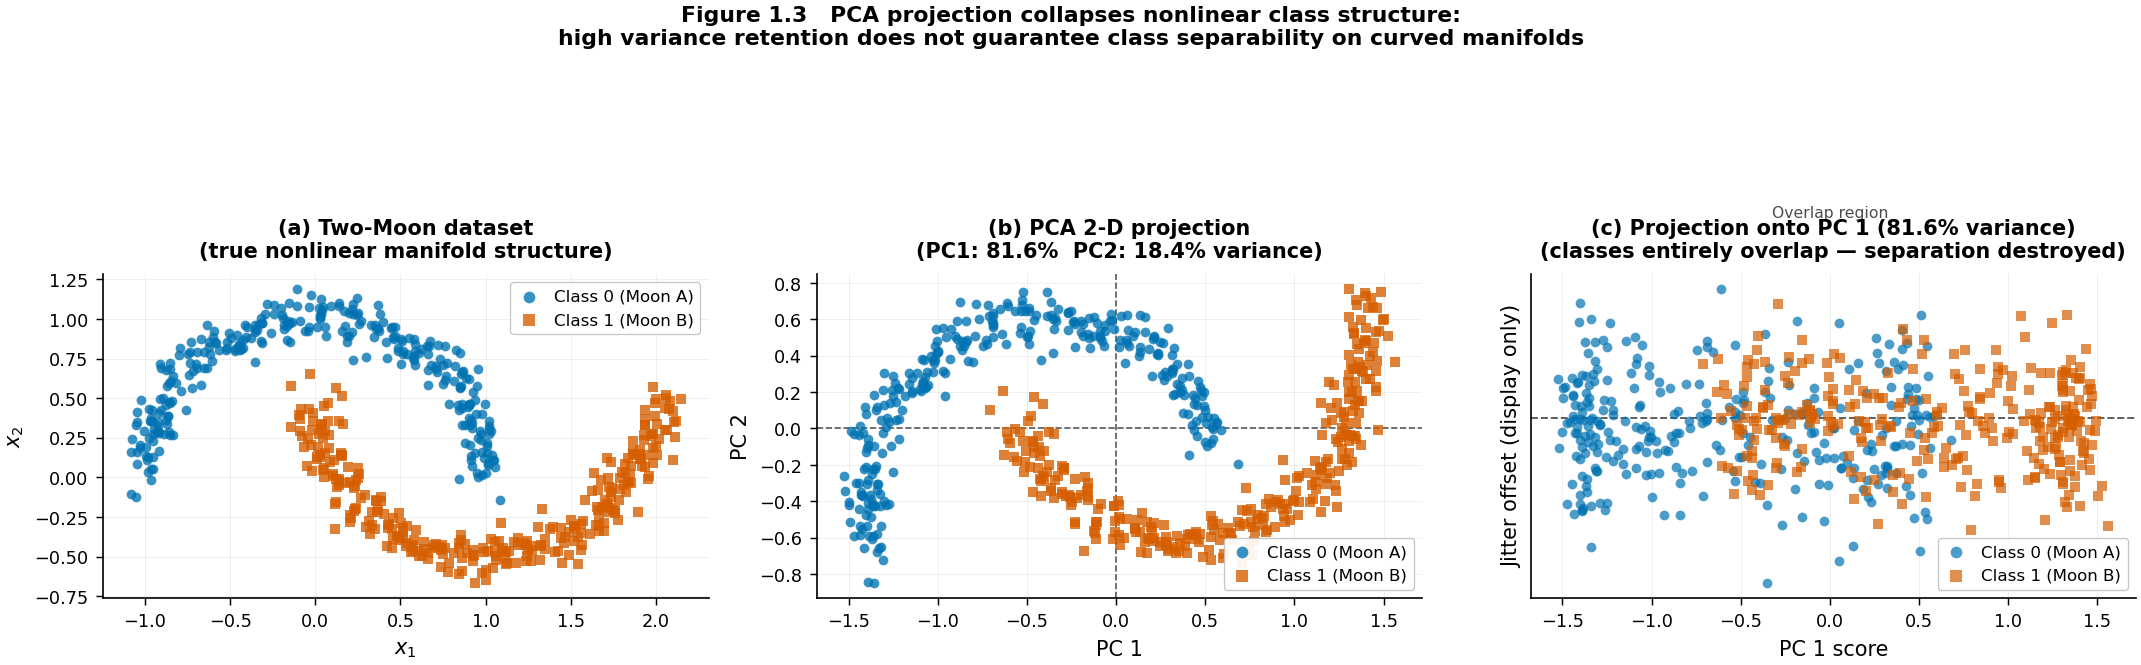

Figure 1.3 saved  (fig1_3_pca_moons.pdf, 300 DPI)


In [ ]:

# ── Figure 1.4  PCA fails on nonlinear (Two-Moon) data ────────────────────
X_moon, y_moon   = make_moons(n_samples=600, noise=0.07, random_state=42)
pca_moon          = PCA(n_components=2)
X_moon_pca        = pca_moon.fit_transform(X_moon)
var1, var2        = pca_moon.explained_variance_ratio_

MOON_COL = [CB['blue'], CB['red']]
MOON_LBL = ['Class 0 (Moon A)', 'Class 1 (Moon B)']
MOON_MRK = ['o', 's']

def _scatter_classes(ax, X, y, s=22, alpha=0.78):
    for k in range(2):
        mask = y == k
        ax.scatter(X[mask, 0], X[mask, 1],
                   c=MOON_COL[k], marker=MOON_MRK[k],
                   s=s, alpha=alpha, linewidths=0,
                   label=MOON_LBL[k], zorder=3, rasterized=True)

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.6))

# ── Panel (a): true nonlinear structure ───────────────────────────────────
_scatter_classes(axes[0], X_moon, y_moon)
axes[0].set_xlabel('$x_1$')
axes[0].set_ylabel('$x_2$')
axes[0].set_title('(a) Two-Moon dataset\n(true nonlinear manifold structure)', fontsize=10)
axes[0].legend(framealpha=0.92, edgecolor='0.75', markerscale=1.2, fontsize=8)

# ── Panel (b): PCA 2-D projection ─────────────────────────────────────────
_scatter_classes(axes[1], X_moon_pca, y_moon)
axes[1].set_xlabel('PC 1')
axes[1].set_ylabel('PC 2')
axes[1].set_title(f'(b) PCA 2-D projection\n'
                  f'(PC1: {var1*100:.1f}%  PC2: {var2*100:.1f}% variance)',
                  fontsize=10)
axes[1].legend(framealpha=0.92, edgecolor='0.75', markerscale=1.2, fontsize=8)
axes[1].axhline(0, color='0.35', linewidth=0.8, linestyle='--', zorder=1)
axes[1].axvline(0, color='0.35', linewidth=0.8, linestyle='--', zorder=1)

# ── Panel (c): 1-D projection — complete class overlap ────────────────────
rng    = np.random.default_rng(7)
jitter = rng.normal(0, 0.016, len(X_moon))
pc1    = X_moon_pca[:, 0]

for k in range(2):
    mask = y_moon == k
    axes[2].scatter(pc1[mask], jitter[mask],
                    c=MOON_COL[k], marker=MOON_MRK[k],
                    s=22, alpha=0.70, linewidths=0,
                    label=MOON_LBL[k], zorder=3, rasterized=True)

axes[2].axhline(0, color='0.35', linewidth=0.9, linestyle='--', zorder=1)
axes[2].set_xlabel('PC 1 score')
axes[2].set_ylabel('Jitter offset (display only)')
axes[2].set_yticks([])
axes[2].set_title(f'(c) Projection onto PC 1 ({var1*100:.1f}% variance)\n'
                  '(classes entirely overlap — separation destroyed)', fontsize=10)
axes[2].legend(framealpha=0.92, edgecolor='0.75', markerscale=1.2, fontsize=8)

yb = 0.055
axes[2].annotate('',
    xy=(pc1.max() * 0.96, yb), xytext=(pc1.min() * 0.96, yb),
    arrowprops=dict(arrowstyle='<->', color='0.30', lw=1.0))
axes[2].text(pc1.mean(), yb + 0.008, 'Overlap region',
             ha='center', fontsize=7.5, color='0.30')

fig.suptitle(
    'Figure 1.4   PCA projection collapses nonlinear class structure:\n'
    'high variance retention does not guarantee class separability on curved manifolds',
    fontsize=10.5, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.87])

fig.savefig('pictures/fig1_4_pca_moons.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Figure 1.4 saved  (fig1_4_pca_moons.pdf, 300 DPI)")



---
## 1.3b  A Nonlinear Baseline: t-SNE

**t-Distributed Stochastic Neighbor Embedding (t-SNE)** directly targets the problem PCA fails at: it models local, nonlinear structure by matching pairwise similarities between points.

### Formulation

Define the high-dimensional similarity between $x_i$ and $x_j$ using a Gaussian kernel with per-point bandwidth $\sigma_i$:

$$p_{ij} = \frac{p_{j|i} + p_{i|j}}{2n}, \qquad p_{j|i} = \frac{\exp\!\left(-\|x_i - x_j\|^2 / 2\sigma_i^2\right)}{\displaystyle\sum_{k \ne i}\exp\!\left(-\|x_i - x_k\|^2 / 2\sigma_i^2\right)}$$

In the low-dimensional embedding $y_i \in \mathbb{R}^m$, a heavier-tailed Student-$t$ distribution is used:

$$q_{ij} = \frac{\left(1 + \|y_i - y_j\|^2\right)^{-1}}{\displaystyle\sum_{k \ne l}\left(1 + \|y_k - y_l\|^2\right)^{-1}}$$

The embedding is found by minimising the KL-divergence:

$$\mathcal{L} = \mathrm{KL}(P \,\|\, Q) = \sum_{i,j} p_{ij} \log \frac{p_{ij}}{q_{ij}}$$

### Key hyperparameter: Perplexity

The **perplexity** $\mathcal{P}$ controls the effective neighbourhood size and the bandwidth $\sigma_i$ of each Gaussian. It is the most influential hyperparameter — small values focus on very local structure while large values approach a more global view:

| Perplexity | Effect |
|-----------|--------|
| Too small ($< 10$) | Points only see their nearest few neighbours → topology fragments |
| Balanced ($\approx 30$) | Captures local manifold geometry faithfully |
| Too large ($> 80$) | Effective neighbourhood covers most of data → structure collapses |

### Limitations vs. Diffusion Map

| Issue | t-SNE | Diffusion Map |
|-------|-------|---------------|
| Stochastic | Yes — results vary across runs | No — deterministic spectral decomposition |
| Out-of-sample | No — cannot embed new points | Yes — via Nyström extension |
| Global geometry | **Not preserved** — cluster spacings are meaningless | Preserved via diffusion distance |
| Interpretability | Low — axes have no meaning | Higher — each axis = diffusion coordinate |

> *t-SNE often produces visually appealing clusters, but the **distances between clusters are not interpretable** — only local structure is preserved.*  
> Diffusion Map retains a coherent multi-scale geometry that supports downstream analysis beyond visualisation.


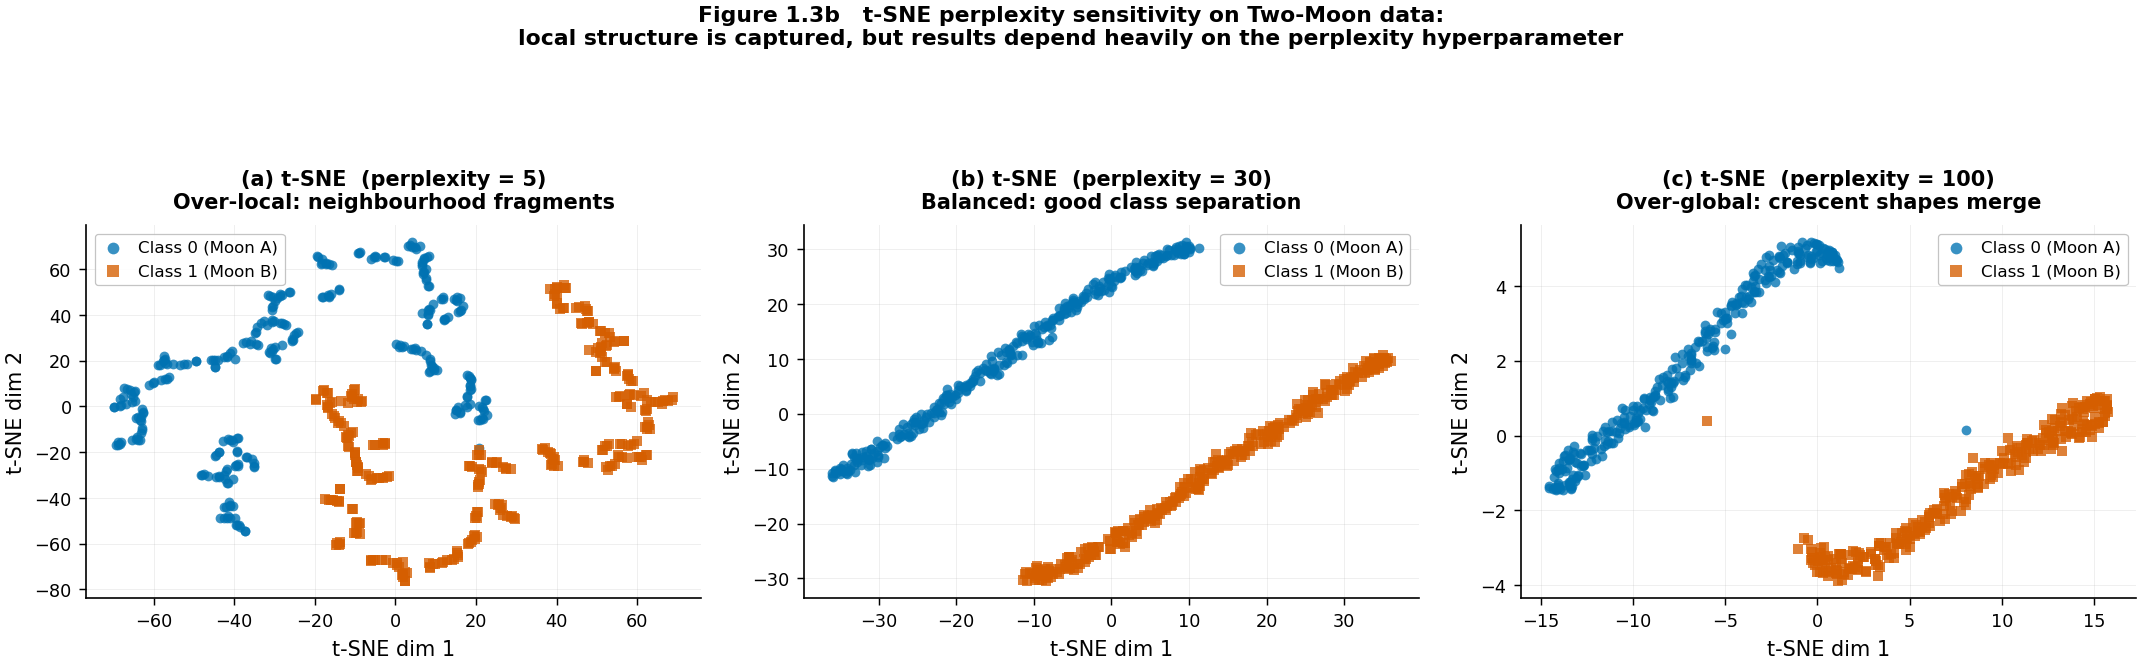

In [ ]:

# ── Figure 1.5  t-SNE: perplexity sensitivity on Two-Moon ────────────────
from sklearn.manifold import TSNE

X_tsne, y_tsne = make_moons(n_samples=600, noise=0.07, random_state=42)

perplexities  = [5, 30, 100]
panel_labels  = ['(a)', '(b)', '(c)']
panel_descs   = [
    't-SNE  (perplexity = 5)\nOver-local: neighbourhood fragments',
    't-SNE  (perplexity = 30)\nBalanced: good class separation',
    't-SNE  (perplexity = 100)\nOver-global: crescent shapes merge',
]

MOON_C = [CB['blue'], CB['red']]
MOON_L = ['Class 0 (Moon A)', 'Class 1 (Moon B)']
MOON_M = ['o', 's']

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.6))

for ax, perp, plbl, pdesc in zip(axes, perplexities, panel_labels, panel_descs):
    tsne  = TSNE(n_components=2, perplexity=perp,
                 init='pca', learning_rate='auto',
                 random_state=42)
    X_emb = tsne.fit_transform(X_tsne)

    for k in range(2):
        mask = y_tsne == k
        ax.scatter(X_emb[mask, 0], X_emb[mask, 1],
                   c=MOON_C[k], marker=MOON_M[k],
                   s=22, alpha=0.78, linewidths=0,
                   label=MOON_L[k], zorder=3, rasterized=True)

    ax.set_xlabel('t-SNE dim 1')
    ax.set_ylabel('t-SNE dim 2')
    ax.set_title(f'{plbl} {pdesc}', fontsize=10, fontweight='bold')
    ax.legend(framealpha=0.92, edgecolor='0.75', markerscale=1.2, fontsize=8)

fig.suptitle(
    'Figure 1.5   t-SNE perplexity sensitivity on Two-Moon data:\n'
    'local structure is captured, but results depend heavily on the perplexity hyperparameter',
    fontsize=10.5, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.87])

fig.savefig('pictures/fig1_5_tsne_perplexity.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Figure 1.5 saved  (fig1_5_tsne_perplexity.pdf, 300 DPI)")


---
## 1.4 Diffusion Map as a Nonlinear Alternative

**Diffusion Map** addresses PCA's limitations by replacing linear variance maximisation with **graph-based diffusion geometry**.

### Core pipeline

```
Raw data X  ──►  Affinity graph W  ──►  Markov random walk P  ──►  Spectral embedding
             (kernel similarities)    (diffusion operator)        (diffusion coordinates)
```

### Two key advantages

**① Local neighbourhoods are encoded explicitly**  
Kernel-based affinities make Diffusion Map sensitive to *manifold structure* rather than only global variance.

**② Diffusion time is a natural scale parameter**  
The diffusion time $t$ smooths noise while preserving large-scale connectivity — tunable without recomputing eigenvectors.

$$k(x_i, x_j) = \exp\!\left(-\frac{\|x_i - x_j\|^2}{\varepsilon}\right)$$

The diffusion distance between two points $x_i, x_j$ after $t$ steps is:

$$D_t(x_i,\, x_j)^2 = \sum_{k \geq 1} \left(\lambda_k^t\right)^2 \bigl(\psi_k(x_i) - \psi_k(x_j)\bigr)^2$$

where $\lambda_k, \psi_k$ are eigenvalues/eigenvectors of the normalised diffusion operator.

> *Diffusion Map can capture both **local** and **global** organisation in a single embedding space.*

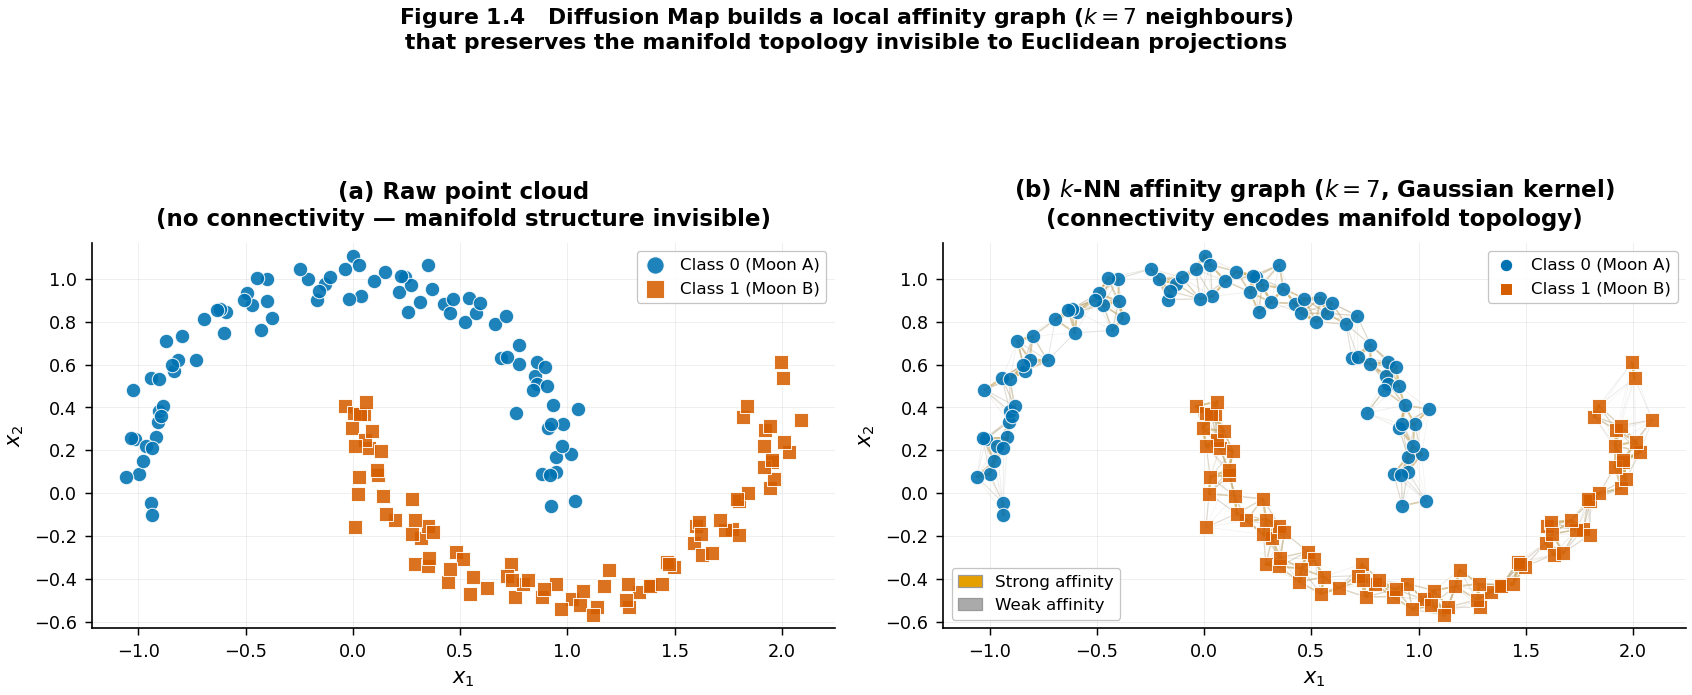

Figure 1.4 saved  (fig1_4_affinity_graph.pdf, 300 DPI)


In [ ]:

# ── Figure 1.6  Affinity graph follows manifold geometry ──────────────────
K = 7
X_small, y_small = make_moons(n_samples=180, noise=0.06, random_state=0)
knn_graph = kneighbors_graph(X_small, n_neighbors=K, mode='connectivity',
                              include_self=False)
cx = sp.coo_matrix(knn_graph)

sq_d   = np.sum((X_small[cx.row] - X_small[cx.col]) ** 2, axis=1)
eps    = np.median(sq_d)
w_edge = np.exp(-sq_d / eps)

MOON_COL = [CB['blue'], CB['red']]
MOON_LBL = ['Class 0 (Moon A)', 'Class 1 (Moon B)']
MOON_MRK = ['o', 's']

EDGE_STRONG = CB['orange']
EDGE_WEAK   = '#AAAAAA'

def _draw_nodes(ax, X, y, s=48):
    for k in range(2):
        mask = y == k
        ax.scatter(X[mask, 0], X[mask, 1],
                   c=MOON_COL[k], marker=MOON_MRK[k],
                   s=s, alpha=0.88, edgecolors='white',
                   linewidths=0.5, zorder=4, label=MOON_LBL[k])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))

# ── Panel (a): raw point cloud ─────────────────────────────────────────────
_draw_nodes(axes[0], X_small, y_small)
axes[0].set_xlabel('$x_1$')
axes[0].set_ylabel('$x_2$')
axes[0].set_title('(a) Raw point cloud\n'
                  '(no connectivity — manifold structure invisible)')
axes[0].legend(framealpha=0.92, edgecolor='0.75', markerscale=1.2, fontsize=8,
               loc='upper right')
axes[0].set_aspect('equal', adjustable='datalim')

# ── Panel (b): k-NN affinity graph — edges coloured by weight ─────────────
for i, j, w in zip(cx.row, cx.col, w_edge):
    xi, xj = X_small[i], X_small[j]
    r = float(w)
    color = (
        (1 - r) * np.array(mpl.colors.to_rgb(EDGE_WEAK)) +
        r        * np.array(mpl.colors.to_rgb(EDGE_STRONG))
    )
    axes[1].plot([xi[0], xj[0]], [xi[1], xj[1]],
                 color=color,
                 alpha=r * 0.55 + 0.15,
                 linewidth=r * 1.4 + 0.3,
                 solid_capstyle='round', zorder=1)

_draw_nodes(axes[1], X_small, y_small)
axes[1].set_xlabel('$x_1$')
axes[1].set_ylabel('$x_2$')
axes[1].set_title(f'(b) $k$-NN affinity graph ($k = {K}$, Gaussian kernel)\n'
                  '(connectivity encodes manifold topology)')
axes[1].set_aspect('equal', adjustable='datalim')

# ── Legend 1: class markers — upper right ────────────────────────────────
node_handles = [
    plt.scatter([], [], c=MOON_COL[k], marker=MOON_MRK[k], s=36,
                label=MOON_LBL[k], edgecolors='white', linewidths=0.5)
    for k in range(2)
]
leg1 = axes[1].legend(handles=node_handles, loc='upper right',
                      framealpha=0.92, edgecolor='0.75', fontsize=8)
axes[1].add_artist(leg1)

# ── Legend 2: edge colours — lower left ──────────────────────────────────
edge_handles = [
    mpatches.Patch(facecolor=EDGE_STRONG, edgecolor='0.6', label='Strong affinity'),
    mpatches.Patch(facecolor=EDGE_WEAK,   edgecolor='0.6', label='Weak affinity'),
]
axes[1].legend(handles=edge_handles, loc='lower left',
               framealpha=0.92, edgecolor='0.75', fontsize=8)

fig.suptitle(
    f'Figure 1.6   Diffusion Map builds a local affinity graph ($k = {K}$ neighbours)\n'
    'that preserves the manifold topology invisible to Euclidean projections',
    fontsize=10.5, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.87])

fig.savefig('pictures/fig1_6_affinity_graph.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Figure 1.6 saved  (fig1_6_affinity_graph.pdf, 300 DPI)")



---
## 1.5 Objectives and Scope of This Report

This report develops an **academic and implementation-oriented study** of Technical Diffusion Map with the following goals:

1. **Mathematical foundation** — Formulate the method from affinity construction to spectral embedding.  
2. **Reproducible workflow** — Establish a clear strategy for parameter selection and computational implementation.  
3. **Comparative evaluation** — Compare Diffusion Map with PCA and t-SNE under consistent evaluation criteria.  
4. **Practical analysis** — Analyse strengths, limitations, and deployment considerations for technical data.  

### Scope

> The focus is on **methodological rigour and empirical interpretability** rather than proposing a new manifold-learning algorithm.  
> The intended contribution is a clear bridge between *theoretical formulation* and *practical usage* in data-analysis pipelines.

---
## 1.6 Report Organisation

| Chapter | Title | Content |
|---------|-------|---------|
| **2** | Theoretical Foundation | Graph construction, transition operators, diffusion distance |
| **3** | Methodology | Implementation workflow, hyperparameter strategy |
| **4** | Experiments & Results | Comparative experiments, quantitative evaluation |
| **5** | Discussion & Conclusion | Implications, limitations, concluding remarks |

---

**End of Chapter 1 — Introduction**  
➡ Proceed to [Chapter 2: Theoretical Foundation](./02_theoretical_foundation.ipynb)
